In [1]:
import time
import resource

# Start the global timer
notebook_start_time = time.time()
print("Automated profiling started...")

Automated profiling started...


In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/energy-anomaly-detection/sample_submission.csv
/kaggle/input/competitions/energy-anomaly-detection/train.csv
/kaggle/input/competitions/energy-anomaly-detection/test.csv
/kaggle/input/competitions/energy-anomaly-detection/train_features.csv
/kaggle/input/competitions/energy-anomaly-detection/test_features.csv


In [3]:
!pip install kneed

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
from tqdm import tqdm, trange
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn import metrics
from sklearn.cluster import KMeans
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import RandomOverSampler
from scipy.signal import savgol_filter

import lightgbm as lgb
from kneed import KneeLocator

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objs as go
import plotly
from plotly.offline import download_plotlyjs, init_notebook_mode, plot, iplot
import cufflinks as cf
cf.set_config_file(offline=True)
# Input data files are available i

import datetime

import warnings
warnings.filterwarnings('ignore')

In [5]:
def MinMaxScaler(data):
    return (data-np.min(data))/(np.max(data)-np.min(data))

def Kmeans_clustering(df, clusterNum, max_iter=1000, n_jobs=-1):
    '''
    Function for doing kmeans clustering.
    Inputs should include at least the dataframe of variables and cluster number you want.
    '''
    # Normalize the dataframe
    scaler = StandardScaler()
    scaler.fit(df) 
    df_std = pd.DataFrame(data=scaler.transform(df), columns=df.columns, index=df.index)
    
    # Kmeans clustering
    km_model = KMeans(n_clusters=clusterNum, max_iter=max_iter, random_state=666)
    km_model = km_model.fit(df_std)
    
    clusterdf= pd.DataFrame(data=km_model.labels_, columns=['ClusterNo'])
    clusterdf.index = df.index
    
    return clusterdf

def Kmeans_bestClusterNum(df, range_min, range_max, max_iter=1000, n_jobs=-1):
    '''
    Function for finding optimal number of kmeans clustering.
    Inputs should include at least the dataframe of variables, and search range of cluster number (min & max cluster number).
    '''    
    
    # Normalize the dataframe
    scaler = StandardScaler()
    scaler.fit(df) 
    df_std = pd.DataFrame(data=scaler.transform(df), columns=df.columns, index=df.index)       
    
    # Calculate inertia for each cluster number in the research range
    sum_of_squared_distances = [] #Inertia of all clustering results
    ks = range(range_min,range_max+1)
    for k in ks:
        kmeans_fit = KMeans(n_clusters = k, max_iter=max_iter, random_state=666).fit(df_std)
        cluster_labels = kmeans_fit.labels_
        sum_of_squared_distances.append(kmeans_fit.inertia_)
        
    # Use kneed package to locate the elbow / knee of the curve line
    kn = KneeLocator(list(ks), sum_of_squared_distances, S=1.0, curve='convex', direction='decreasing')  
    
    # Plot the result of finding optimal cluster number
    plt.xlabel('k')
    plt.ylabel('sum_of_squared_distances')
    plt.title('The Elbow Method showing the optimal k')
    plt.plot(ks, sum_of_squared_distances, 'bx-')
    plt.vlines(kn.knee, plt.ylim()[0], plt.ylim()[1], linestyles='dashed')
    plt.show()
    
    print('Optimal clustering number:'+str(kn.knee))
    print('----------------------------')    
    
    return kn.knee

In [6]:
train_features = pd.read_csv('/kaggle/input/competitions/energy-anomaly-detection/train_features.csv')
train_features['cloud_coverage'] = train_features['cloud_coverage'].replace({255:10})

In [7]:
test_features = pd.read_csv('/kaggle/input/competitions/energy-anomaly-detection/test_features.csv', index_col=0)
test_features['cloud_coverage'] = test_features['cloud_coverage'].replace({255:10})

In [8]:
merged_data = pd.concat([train_features, test_features],axis=0,ignore_index=True)
merged_data_pivot = merged_data.pivot_table(index='timestamp',columns='building_id',values='meter_reading')

# remove outliers (10 std away from avg)
merged_data_pivot = (merged_data_pivot-merged_data_pivot.mean())/merged_data_pivot.std()
merged_data_pivot = merged_data_pivot[merged_data_pivot<10]
merged_data_pivot = merged_data_pivot[merged_data_pivot>-10]

merged_data_pivot = (merged_data_pivot-merged_data_pivot.mean())/merged_data_pivot.std()
merged_data_pivot = merged_data_pivot[merged_data_pivot<10]
merged_data_pivot = merged_data_pivot[merged_data_pivot>-10]

merged_data_pivot.index = pd.to_datetime(merged_data_pivot.index)

merged_data_pivot

building_id,1,18,19,26,32,38,39,41,55,69,...,1317,1318,1319,1320,1321,1322,1323,1353,1384,1425
timestamp,,,,,,,,,,,,,,,,,,,,,
2016-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.782113,-1.222397,-0.295801,-0.724083,-0.491904,-0.581884,-0.121795,-0.855589,-0.896302,-1.086031
2016-01-01 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.785629,-1.379572,-0.590580,-0.723904,-0.612916,-0.824660,-0.050955,-0.835054,-0.896302,-1.055597
2016-01-01 02:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.797065,-1.222410,-1.180016,-0.872948,-0.722403,-0.750251,-0.121795,-0.848744,-0.735114,-1.021960
2016-01-01 03:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.808502,-1.052165,-0.590580,-0.415254,-0.676303,-0.562336,-0.357927,-0.876124,-1.218678,-1.102049
2016-01-01 04:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.860365,-1.248604,-0.885310,-1.071047,-0.710878,-0.280418,-1.042711,-0.828209,-1.702243,-1.014752
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2016-12-31 19:00:00,-2.118043,0.296662,-1.094677,2.117905,0.668420,1.096717,-0.195342,1.026779,0.278385,0.808463,...,-1.077512,0.337358,NaN,-0.760755,4.100800,-0.246380,-0.145408,-1.259441,-2.024620,-0.896621
2016-12-31 20:00:00,-2.762260,0.194716,-0.946744,1.932770,-0.592391,1.087021,-0.170175,1.038128,0.658975,0.800188,...,-1.040601,0.304288,NaN,-0.746354,3.132702,-0.224326,-0.287087,-1.252596,-1.863431,-1.014352
2016-12-31 21:00:00,-2.717712,0.105477,-1.346097,2.148752,-1.082701,1.016505,-0.226799,1.032404,0.844583,0.816739,...,-1.394012,0.345019,NaN,-1.009660,2.700515,-0.709104,-0.074568,-1.259441,-1.702243,-0.979914


In [9]:
merged_data_pivot = np.log1p(merged_data_pivot)

In [10]:
df_PM_temp = merged_data_pivot.copy()
df_PM_temp = df_PM_temp.T

bestClusterNum_dept = 10
#bestClusterNum_dept = Kmeans_bestClusterNum(df=df_PM_temp.fillna(0), range_min=2, range_max=30, max_iter=10000, n_jobs=-1)

Cluster No.: 0
Amount of meters: 2


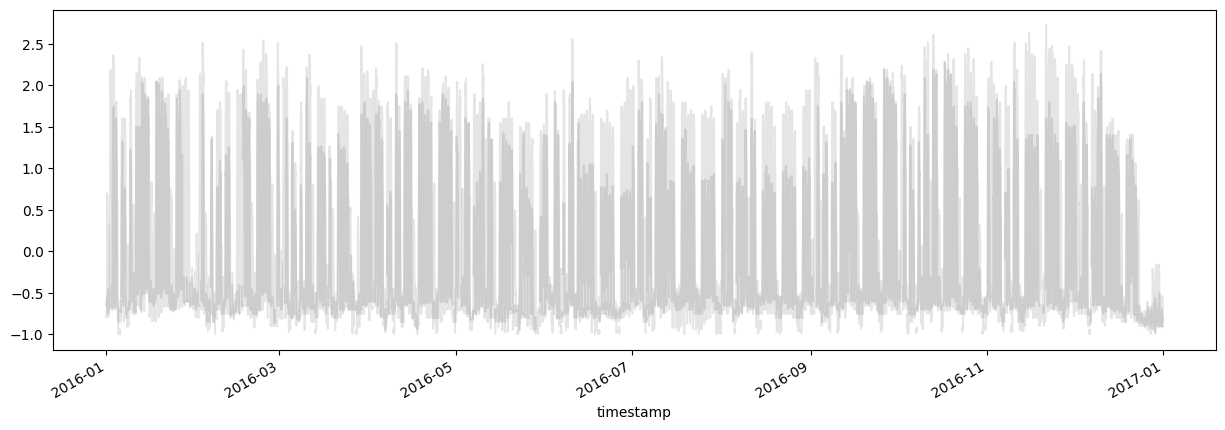

-----------------------------------------------------------------------------------
Cluster No.: 1
Amount of meters: 63


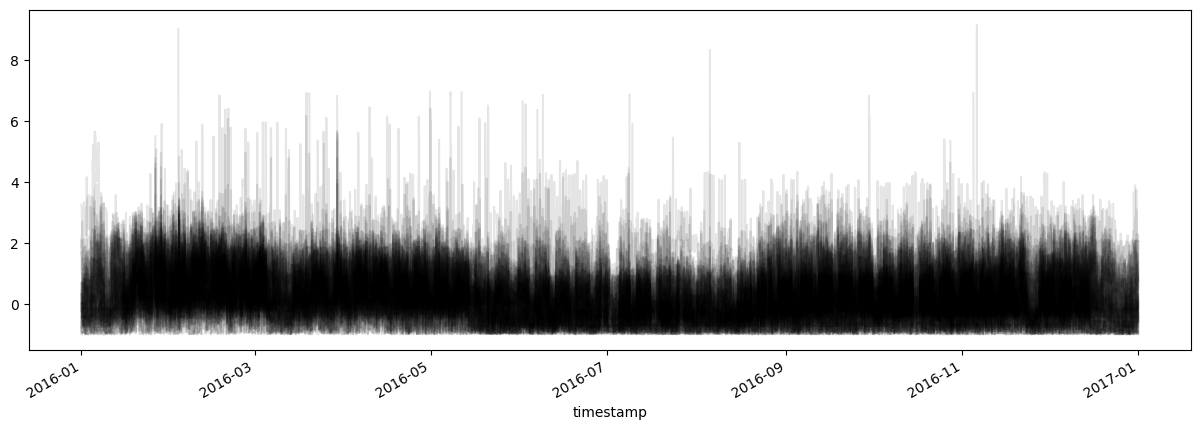

-----------------------------------------------------------------------------------
Cluster No.: 2
Amount of meters: 130


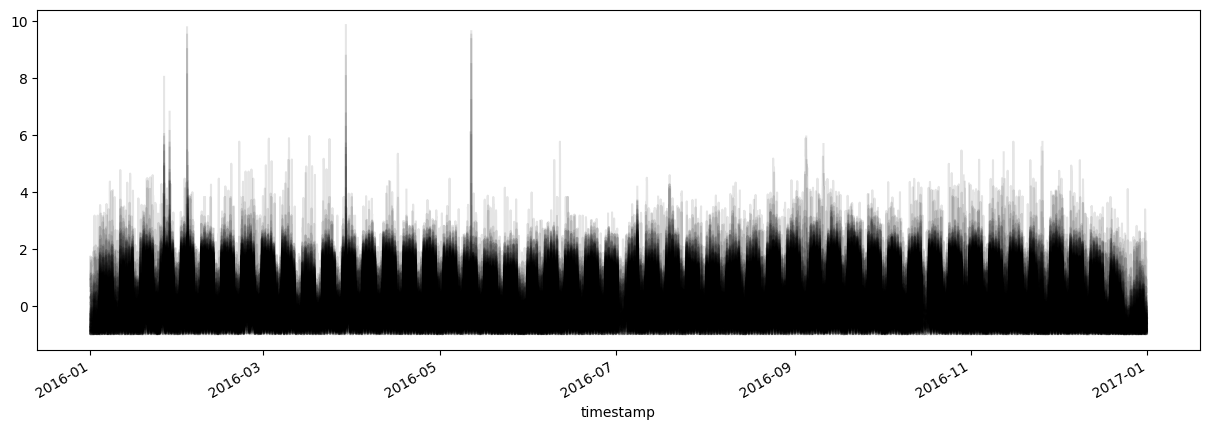

-----------------------------------------------------------------------------------
Cluster No.: 3
Amount of meters: 53


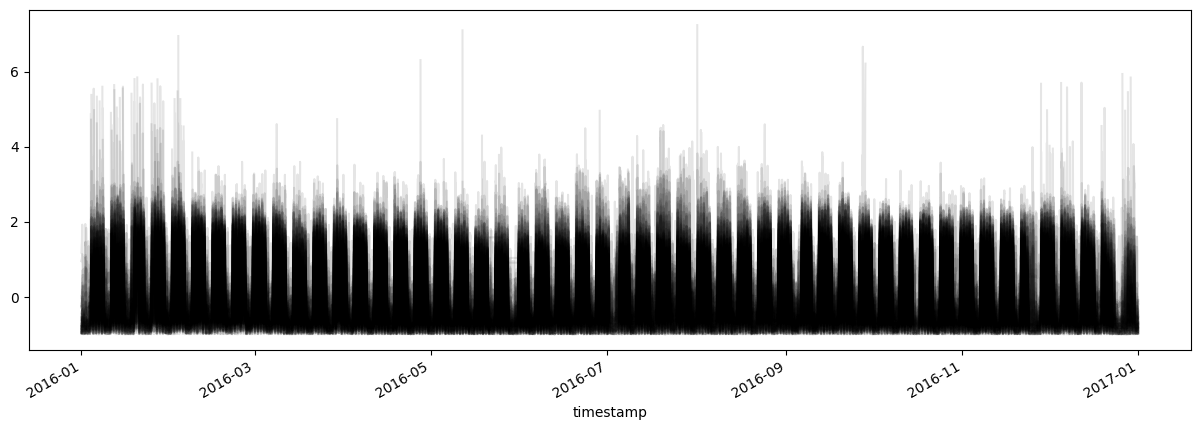

-----------------------------------------------------------------------------------
Cluster No.: 4
Amount of meters: 19


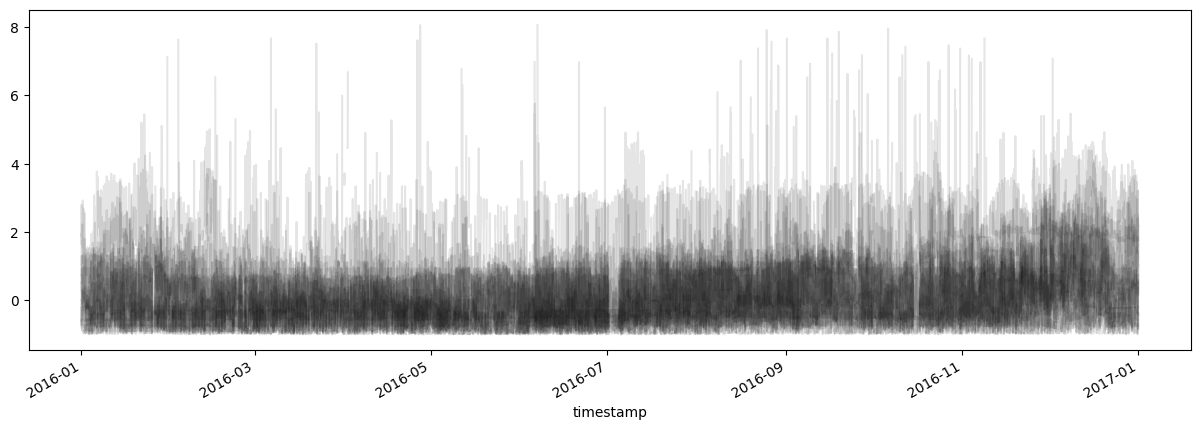

-----------------------------------------------------------------------------------
Cluster No.: 5
Amount of meters: 2


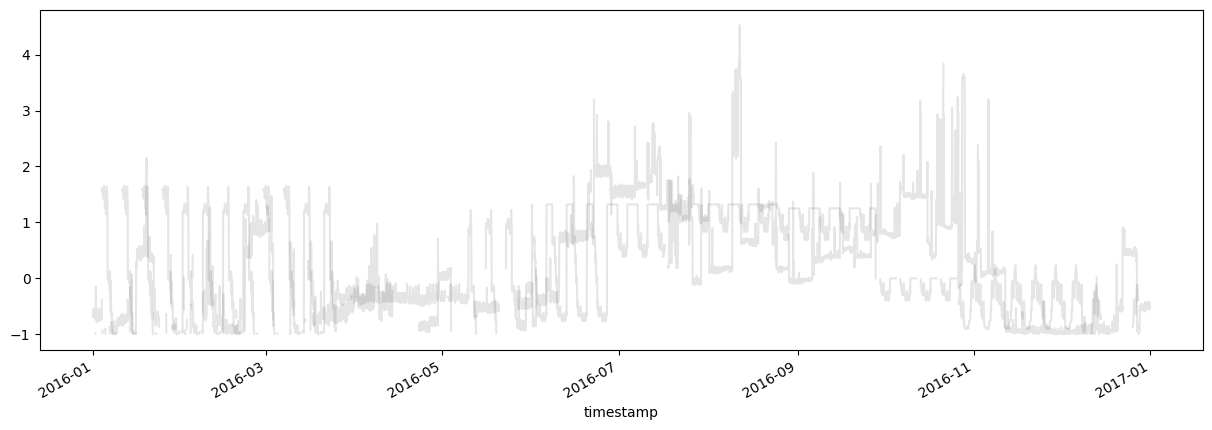

-----------------------------------------------------------------------------------
Cluster No.: 6
Amount of meters: 6


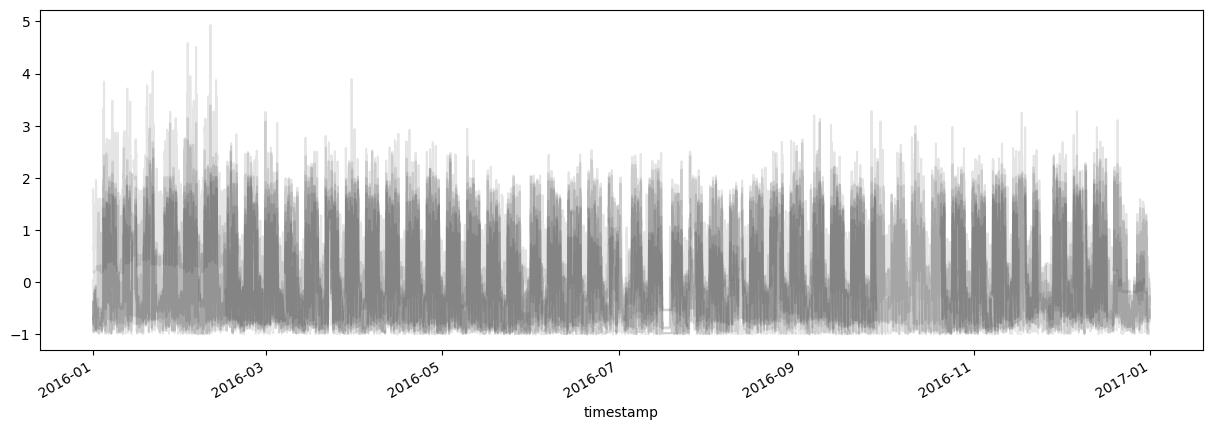

-----------------------------------------------------------------------------------
Cluster No.: 7
Amount of meters: 23


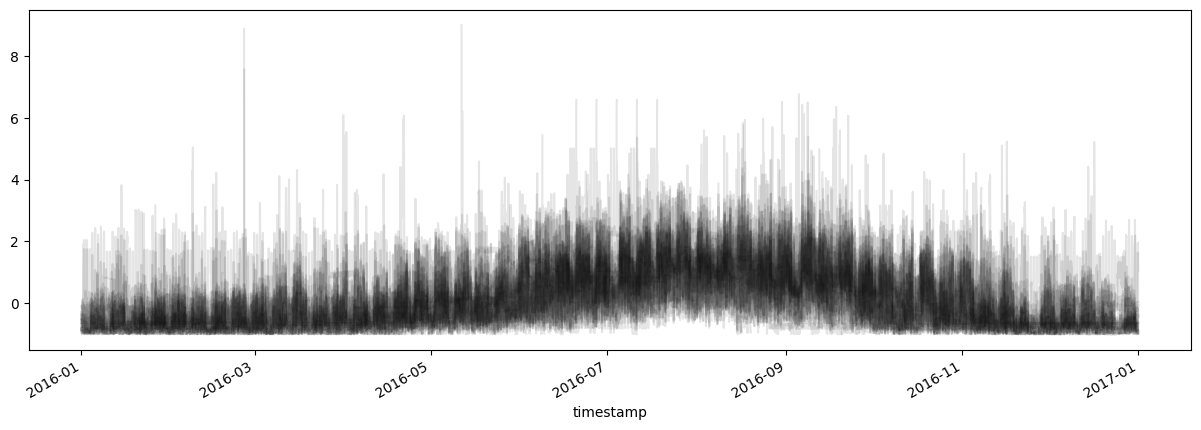

-----------------------------------------------------------------------------------
Cluster No.: 8
Amount of meters: 71


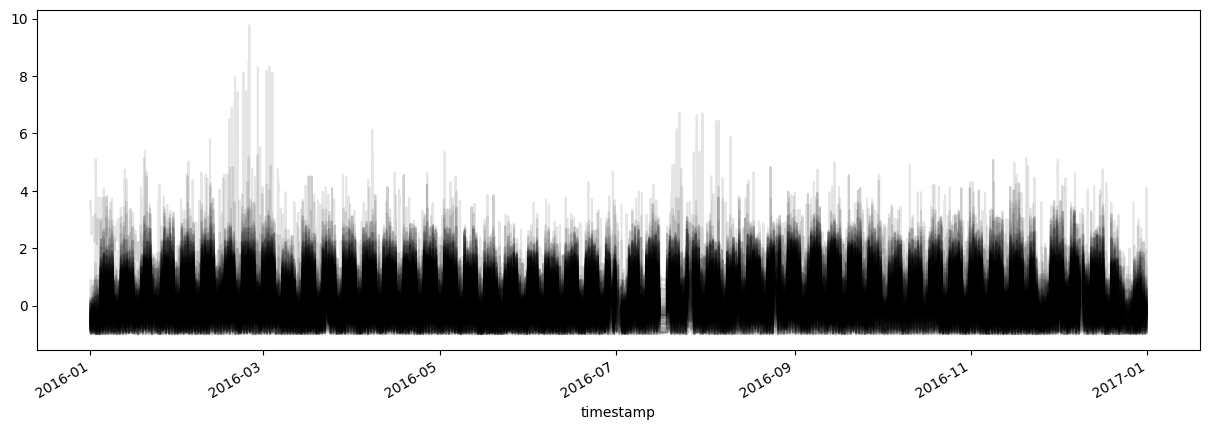

-----------------------------------------------------------------------------------
Cluster No.: 9
Amount of meters: 37


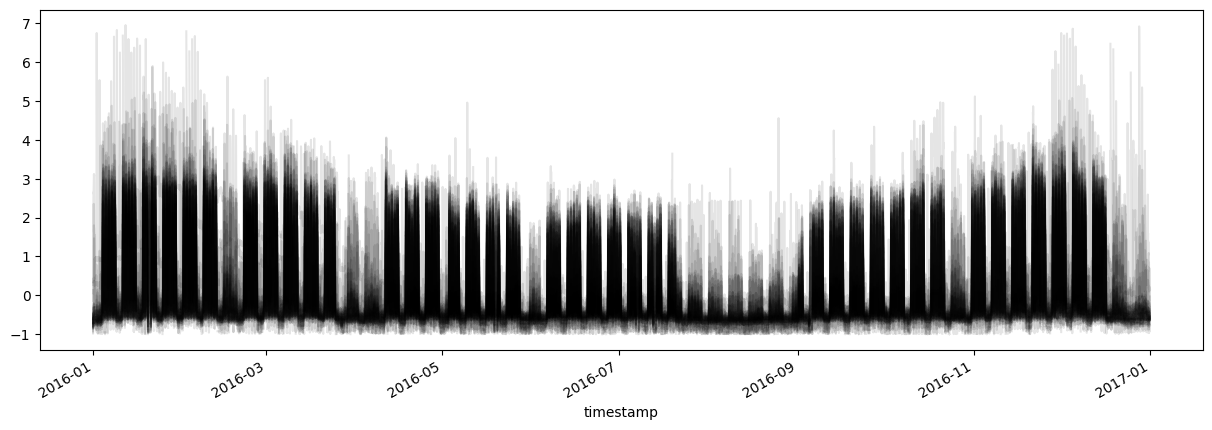

-----------------------------------------------------------------------------------


In [11]:
df_PM_temp['ClusterNo'] = Kmeans_clustering(df=df_PM_temp.fillna(0), clusterNum=bestClusterNum_dept, max_iter=10000, n_jobs=-1)

for ClusterNo in df_PM_temp['ClusterNo'].sort_values().unique():
    df_plot = df_PM_temp[df_PM_temp['ClusterNo']==ClusterNo].T.drop('ClusterNo')
    df_plot = np.expm1(df_plot)
    print('Cluster No.: ' + str(ClusterNo))    
    print('Amount of meters: ' + str(len(df_plot.T)))
    df_plot.plot(figsize=(15,5),color='black',alpha=0.1,legend=False)
    plt.show()
    print('-----------------------------------------------------------------------------------')

In [12]:
train_features = train_features.merge(df_PM_temp['ClusterNo'].reset_index(),on='building_id',how='left')

In [13]:
def impute_nulls(data):
    # FIX: We moved ['meter_reading'] before .mean() so Pandas ignores the timestamp column
    mean_reading = data.groupby('building_id')['meter_reading'].mean()

    building_id = mean_reading.index
    values = mean_reading.values
    
    for i, idx in tqdm(enumerate(building_id)):
        data[data['building_id']==idx] = data[data['building_id']==idx].fillna(values[i]) 
    
    return data

train_features = impute_nulls(train_features)

200it [01:37,  2.05it/s]


In [14]:
#value change features(diff)
train_feature = pd.read_csv('/kaggle/input/competitions/energy-anomaly-detection/train_features.csv')
for shift_hours in tqdm(list(np.arange(-24,0))+list(np.arange(1,24+1))+list(np.arange(-24*7,-24,24))+list(np.arange(24+24,24*7+1,24))):
    shift_hours = int(shift_hours)
    meter_reading_shift = train_feature[['building_id', 'timestamp', 'meter_reading']]
    meter_reading_shift['timestamp'] = pd.to_datetime(meter_reading_shift['timestamp']) + datetime.timedelta(hours=shift_hours)
    meter_reading_shift['timestamp'] = meter_reading_shift['timestamp'].astype('str')
    meter_reading_shift = meter_reading_shift.rename(columns={'meter_reading':'lag_value_'+str(shift_hours)})
    train_feature = train_feature.merge(meter_reading_shift, on=['building_id', 'timestamp'], how='left')
    
    train_features['lag_value_'+str(shift_hours)] = train_feature['lag_value_'+str(shift_hours)]-train_feature['meter_reading']

100%|██████████| 60/60 [04:33<00:00,  4.55s/it]


In [15]:
#value change features(ratio)
train_feature = pd.read_csv('/kaggle/input/competitions/energy-anomaly-detection/train_features.csv')
for shift_hours in tqdm(list(np.arange(-24,0))+list(np.arange(1,24+1))+list(np.arange(-24*7,-24,24))+list(np.arange(24+24,24*7+1,24))):
    shift_hours = int(shift_hours)
    meter_reading_shift = train_feature[['building_id', 'timestamp', 'meter_reading']]
    meter_reading_shift['timestamp'] = pd.to_datetime(meter_reading_shift['timestamp']) + datetime.timedelta(hours=shift_hours)
    meter_reading_shift['timestamp'] = meter_reading_shift['timestamp'].astype('str')
    meter_reading_shift = meter_reading_shift.rename(columns={'meter_reading':'lag_value_'+str(shift_hours)})
    train_feature = train_feature.merge(meter_reading_shift, on=['building_id', 'timestamp'], how='left')
    
    train_features['lag_value_ratio_'+str(shift_hours)] = (train_feature['lag_value_'+str(shift_hours)]+1)/(train_feature['meter_reading']+1)

100%|██████████| 60/60 [04:25<00:00,  4.42s/it]


In [16]:
df_savgol_train = []

for building_id in tqdm(train_features['building_id'].unique()):
    df_temp = train_features[train_features['building_id']==building_id]
    df_temp['meter_reading_smooth'] = savgol_filter(df_temp['meter_reading'].fillna(method='ffill'), 5, 3)
    df_temp['Residual_savgol_w5p3'] = (df_temp['meter_reading'] - df_temp['meter_reading_smooth'])
    df_savgol_train.append(df_temp)
    
df_savgol_train = pd.concat(df_savgol_train,axis=0).sort_index()
df_savgol_train

100%|██████████| 200/200 [00:07<00:00, 27.15it/s]


,building_id,timestamp,meter_reading,anomaly,site_id,primary_use,square_feet,year_built,floor_count,air_temperature,...,lag_value_ratio_-72,lag_value_ratio_-48,lag_value_ratio_48,lag_value_ratio_72,lag_value_ratio_96,lag_value_ratio_120,lag_value_ratio_144,lag_value_ratio_168,meter_reading_smooth,Residual_savgol_w5p3
0,1,2016-01-01 00:00:00,35.267879,0,0,Education,2720,104,0,19.4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.267879,2.842171e-14
1,32,2016-01-01 00:00:00,98.400360,0,0,Office,48392,105,0,19.4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,98.400360,7.105427e-14
2,41,2016-01-01 00:00:00,61.162877,0,0,Office,93860,68,0,19.4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,61.162877,0.000000e+00
3,55,2016-01-01 00:00:00,33.911298,0,0,Office,16726,111,0,19.4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,33.911298,2.842171e-14
4,69,2016-01-01 00:00:00,30.782749,0,0,Parking,387638,100,0,19.4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.782749,7.105427e-15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1749489,1316,2016-12-31 23:00:00,38.844000,0,14,Entertainment/public assembly,49975,255,0,-29.9,...,NaN,NaN,1.003915,0.980373,1.084705,1.092536,1.125489,1.072934,38.933300,-8.930000e-02
1749490,1318,2016-12-31 23:00:00,202.893000,0,14,Entertainment/public assembly,73488,255,0,-29.9,...,NaN,NaN,1.049962,0.981799,0.995522,0.937624,0.917417,0.928379,203.199457,-3.064571e-01
1749491,1319,2016-12-31 23:00:00,132.040616,0,14,Entertainment/public assembly,287419,255,0,-29.9,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,132.040616,1.421085e-13
1749492,1323,2016-12-31 23:00:00,172.000000,0,14,Office,87200,255,0,-29.9,...,NaN,NaN,1.005780,1.011561,1.028902,0.959538,1.069364,0.953757,170.942857,1.057143e+00


In [17]:
train_features['Residual_savgol_w5p3'] = df_savgol_train['Residual_savgol_w5p3']

In [18]:
train_features.to_pickle('train_features.pickle')
train_features

,building_id,timestamp,meter_reading,anomaly,site_id,primary_use,square_feet,year_built,floor_count,air_temperature,...,lag_value_ratio_-96,lag_value_ratio_-72,lag_value_ratio_-48,lag_value_ratio_48,lag_value_ratio_72,lag_value_ratio_96,lag_value_ratio_120,lag_value_ratio_144,lag_value_ratio_168,Residual_savgol_w5p3
0,1,2016-01-01 00:00:00,35.267879,0,0,Education,2720,104,0,19.4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.842171e-14
1,32,2016-01-01 00:00:00,98.400360,0,0,Office,48392,105,0,19.4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.105427e-14
2,41,2016-01-01 00:00:00,61.162877,0,0,Office,93860,68,0,19.4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000e+00
3,55,2016-01-01 00:00:00,33.911298,0,0,Office,16726,111,0,19.4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.842171e-14
4,69,2016-01-01 00:00:00,30.782749,0,0,Parking,387638,100,0,19.4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.105427e-15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1749489,1316,2016-12-31 23:00:00,38.844000,0,14,Entertainment/public assembly,49975,255,0,-29.9,...,NaN,NaN,NaN,1.003915,0.980373,1.084705,1.092536,1.125489,1.072934,-8.930000e-02
1749490,1318,2016-12-31 23:00:00,202.893000,0,14,Entertainment/public assembly,73488,255,0,-29.9,...,NaN,NaN,NaN,1.049962,0.981799,0.995522,0.937624,0.917417,0.928379,-3.064571e-01
1749491,1319,2016-12-31 23:00:00,132.040616,0,14,Entertainment/public assembly,287419,255,0,-29.9,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.421085e-13
1749492,1323,2016-12-31 23:00:00,172.000000,0,14,Office,87200,255,0,-29.9,...,NaN,NaN,NaN,1.005780,1.011561,1.028902,0.959538,1.069364,0.953757,1.057143e+00


In [19]:
!pip install kneed

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
from tqdm import tqdm, trange
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn import metrics
from sklearn.cluster import KMeans
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import RandomOverSampler
from scipy.signal import savgol_filter

import lightgbm as lgb
from kneed import KneeLocator

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objs as go
import plotly
from plotly.offline import download_plotlyjs, init_notebook_mode, plot, iplot
import cufflinks as cf
cf.set_config_file(offline=True)
# Input data files are available i

import datetime

import warnings
warnings.filterwarnings('ignore')

In [21]:
def MinMaxScaler(data):
    return (data-np.min(data))/(np.max(data)-np.min(data))

def Kmeans_clustering(df, clusterNum, max_iter=1000, n_jobs=-1):
    '''
    Function for doing kmeans clustering.
    Inputs should include at least the dataframe of variables and cluster number you want.
    '''
    # Normalize the dataframe
    scaler = StandardScaler()
    scaler.fit(df) 
    df_std = pd.DataFrame(data=scaler.transform(df), columns=df.columns, index=df.index)
    
    # Kmeans clustering
    km_model = KMeans(n_clusters=clusterNum, max_iter=max_iter, random_state=666)
    km_model = km_model.fit(df_std)
    
    clusterdf= pd.DataFrame(data=km_model.labels_, columns=['ClusterNo'])
    clusterdf.index = df.index
    
    return clusterdf

def Kmeans_bestClusterNum(df, range_min, range_max, max_iter=1000, n_jobs=-1):
    '''
    Function for finding optimal number of kmeans clustering.
    Inputs should include at least the dataframe of variables, and search range of cluster number (min & max cluster number).
    '''    
    
    # Normalize the dataframe
    scaler = StandardScaler()
    scaler.fit(df) 
    df_std = pd.DataFrame(data=scaler.transform(df), columns=df.columns, index=df.index)       
    
    # Calculate inertia for each cluster number in the research range
    sum_of_squared_distances = [] #Inertia of all clustering results
    ks = range(range_min,range_max+1)
    for k in ks:
        kmeans_fit = KMeans(n_clusters = k, max_iter=max_iter, random_state=666).fit(df_std)
        cluster_labels = kmeans_fit.labels_
        sum_of_squared_distances.append(kmeans_fit.inertia_)
        
    # Use kneed package to locate the elbow / knee of the curve line
    kn = KneeLocator(list(ks), sum_of_squared_distances, S=1.0, curve='convex', direction='decreasing')  
    
    # Plot the result of finding optimal cluster number
    plt.xlabel('k')
    plt.ylabel('sum_of_squared_distances')
    plt.title('The Elbow Method showing the optimal k')
    plt.plot(ks, sum_of_squared_distances, 'bx-')
    plt.vlines(kn.knee, plt.ylim()[0], plt.ylim()[1], linestyles='dashed')
    plt.show()
    
    print('Optimal clustering number:'+str(kn.knee))
    print('----------------------------')    
    
    return kn.knee

In [22]:
train_features = pd.read_csv('/kaggle/input/competitions/energy-anomaly-detection/train_features.csv')
train_features['cloud_coverage'] = train_features['cloud_coverage'].replace({255:10})

In [23]:
test_features = pd.read_csv('/kaggle/input/competitions/energy-anomaly-detection/test_features.csv', index_col=0)
test_features['cloud_coverage'] = test_features['cloud_coverage'].replace({255:10})

In [24]:
merged_data = pd.concat([train_features, test_features],axis=0,ignore_index=True)
merged_data_pivot = merged_data.pivot_table(index='timestamp',columns='building_id',values='meter_reading')

# remove outliers (10 std away from avg)
merged_data_pivot = (merged_data_pivot-merged_data_pivot.mean())/merged_data_pivot.std()
merged_data_pivot = merged_data_pivot[merged_data_pivot<10]
merged_data_pivot = merged_data_pivot[merged_data_pivot>-10]

merged_data_pivot = (merged_data_pivot-merged_data_pivot.mean())/merged_data_pivot.std()
merged_data_pivot = merged_data_pivot[merged_data_pivot<10]
merged_data_pivot = merged_data_pivot[merged_data_pivot>-10]

merged_data_pivot.index = pd.to_datetime(merged_data_pivot.index)

merged_data_pivot

building_id,1,18,19,26,32,38,39,41,55,69,...,1317,1318,1319,1320,1321,1322,1323,1353,1384,1425
timestamp,,,,,,,,,,,,,,,,,,,,,
2016-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.782113,-1.222397,-0.295801,-0.724083,-0.491904,-0.581884,-0.121795,-0.855589,-0.896302,-1.086031
2016-01-01 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.785629,-1.379572,-0.590580,-0.723904,-0.612916,-0.824660,-0.050955,-0.835054,-0.896302,-1.055597
2016-01-01 02:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.797065,-1.222410,-1.180016,-0.872948,-0.722403,-0.750251,-0.121795,-0.848744,-0.735114,-1.021960
2016-01-01 03:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.808502,-1.052165,-0.590580,-0.415254,-0.676303,-0.562336,-0.357927,-0.876124,-1.218678,-1.102049
2016-01-01 04:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.860365,-1.248604,-0.885310,-1.071047,-0.710878,-0.280418,-1.042711,-0.828209,-1.702243,-1.014752
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2016-12-31 19:00:00,-2.118043,0.296662,-1.094677,2.117905,0.668420,1.096717,-0.195342,1.026779,0.278385,0.808463,...,-1.077512,0.337358,NaN,-0.760755,4.100800,-0.246380,-0.145408,-1.259441,-2.024620,-0.896621
2016-12-31 20:00:00,-2.762260,0.194716,-0.946744,1.932770,-0.592391,1.087021,-0.170175,1.038128,0.658975,0.800188,...,-1.040601,0.304288,NaN,-0.746354,3.132702,-0.224326,-0.287087,-1.252596,-1.863431,-1.014352
2016-12-31 21:00:00,-2.717712,0.105477,-1.346097,2.148752,-1.082701,1.016505,-0.226799,1.032404,0.844583,0.816739,...,-1.394012,0.345019,NaN,-1.009660,2.700515,-0.709104,-0.074568,-1.259441,-1.702243,-0.979914


In [25]:
merged_data_pivot = np.log1p(merged_data_pivot)

In [26]:
df_PM_temp = merged_data_pivot.copy()
df_PM_temp = df_PM_temp.T

bestClusterNum_dept = 10
#bestClusterNum_dept = Kmeans_bestClusterNum(df=df_PM_temp.fillna(0), range_min=2, range_max=30, max_iter=10000, n_jobs=-1)

Cluster No.: 0
Amount of meters: 2


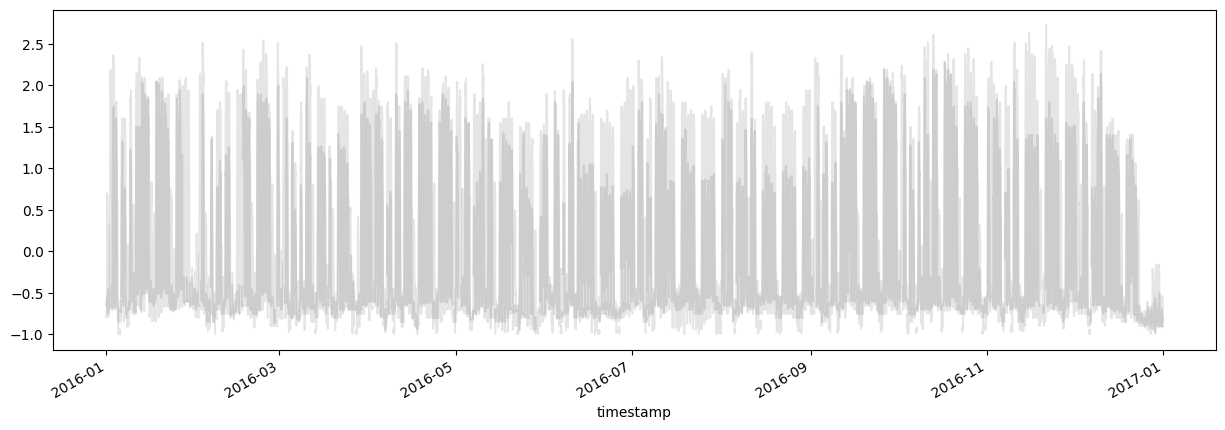

-----------------------------------------------------------------------------------
Cluster No.: 1
Amount of meters: 63


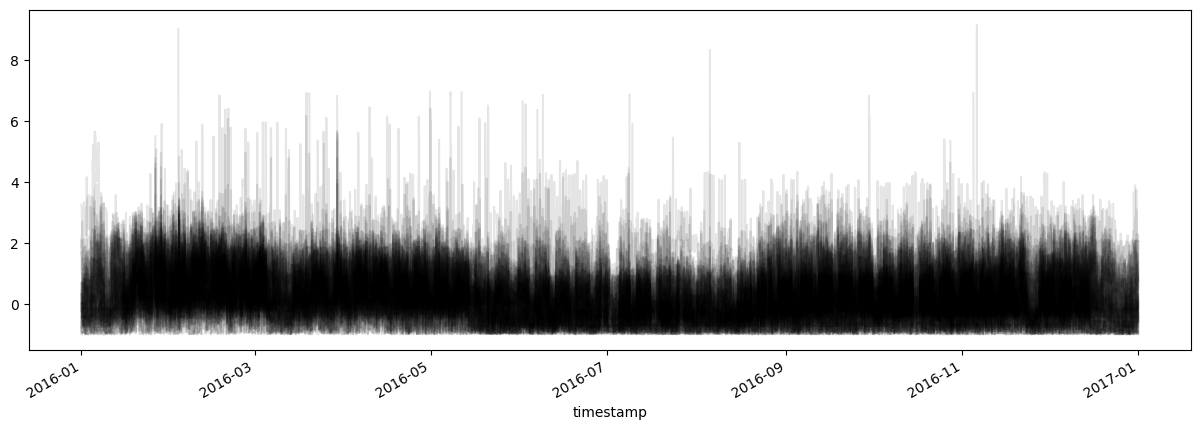

-----------------------------------------------------------------------------------
Cluster No.: 2
Amount of meters: 130


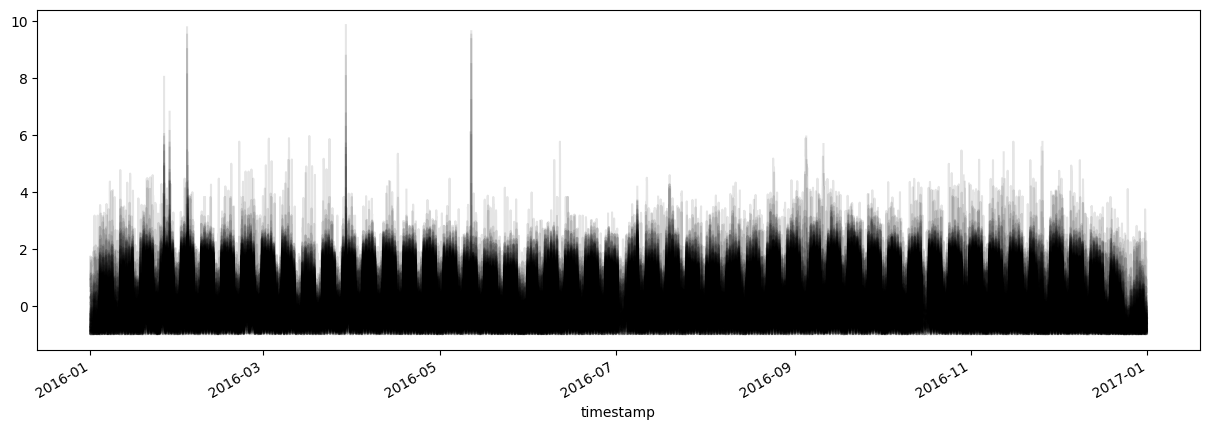

-----------------------------------------------------------------------------------
Cluster No.: 3
Amount of meters: 53


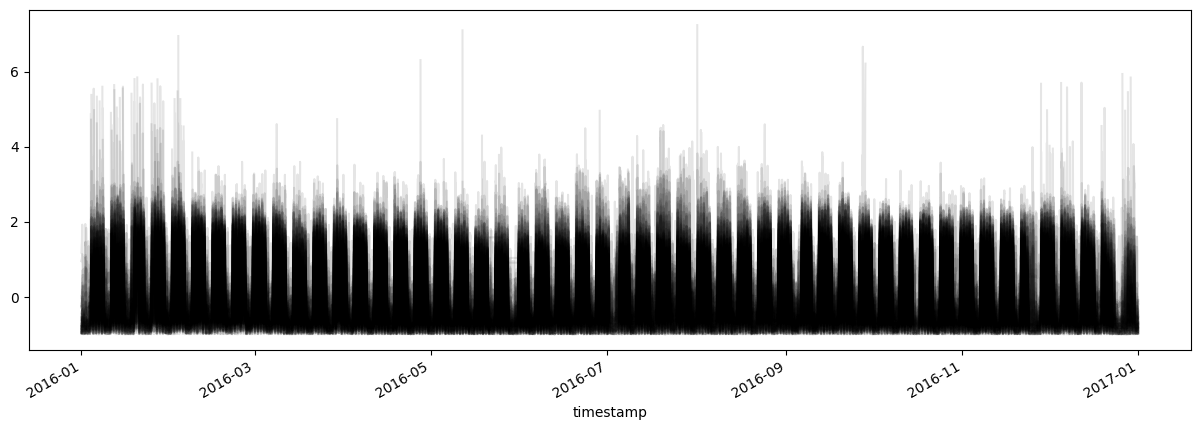

-----------------------------------------------------------------------------------
Cluster No.: 4
Amount of meters: 19


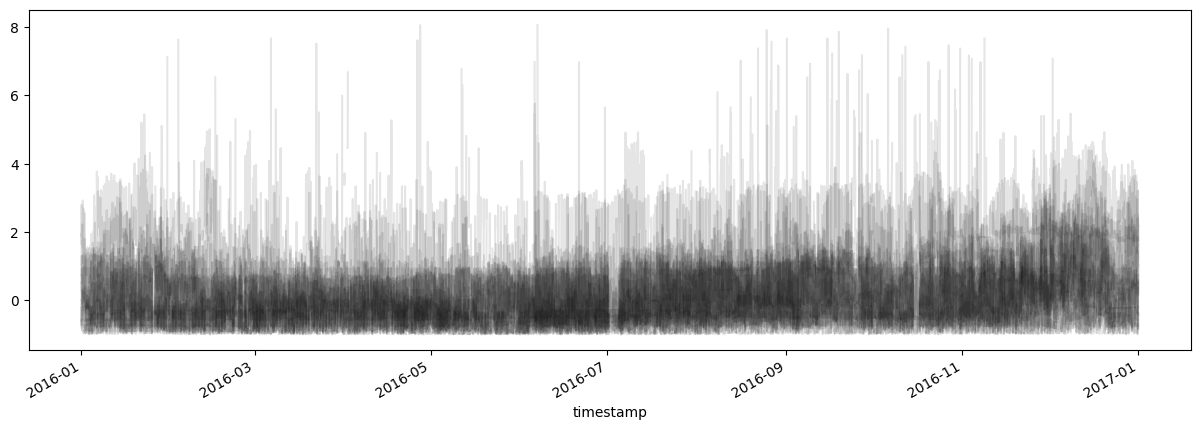

-----------------------------------------------------------------------------------
Cluster No.: 5
Amount of meters: 2


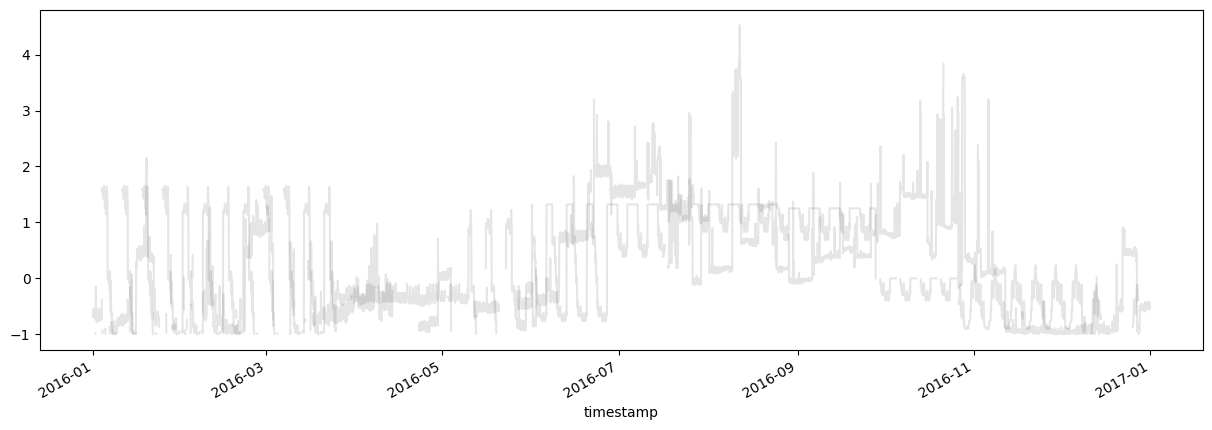

-----------------------------------------------------------------------------------
Cluster No.: 6
Amount of meters: 6


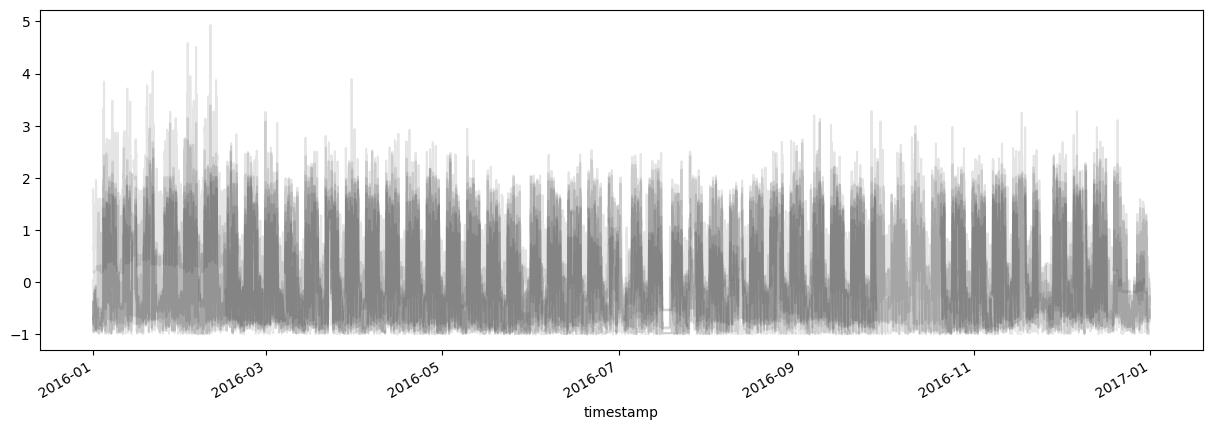

-----------------------------------------------------------------------------------
Cluster No.: 7
Amount of meters: 23


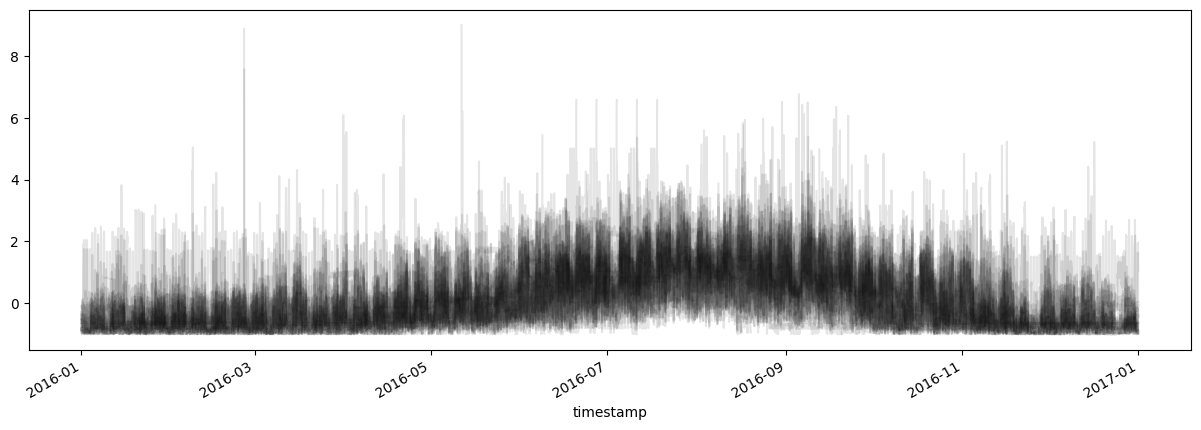

-----------------------------------------------------------------------------------
Cluster No.: 8
Amount of meters: 71


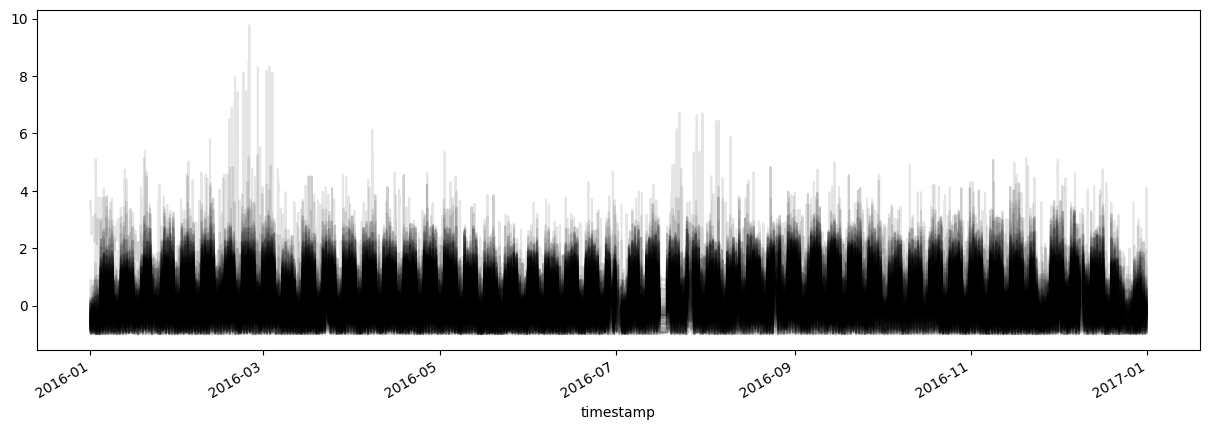

-----------------------------------------------------------------------------------
Cluster No.: 9
Amount of meters: 37


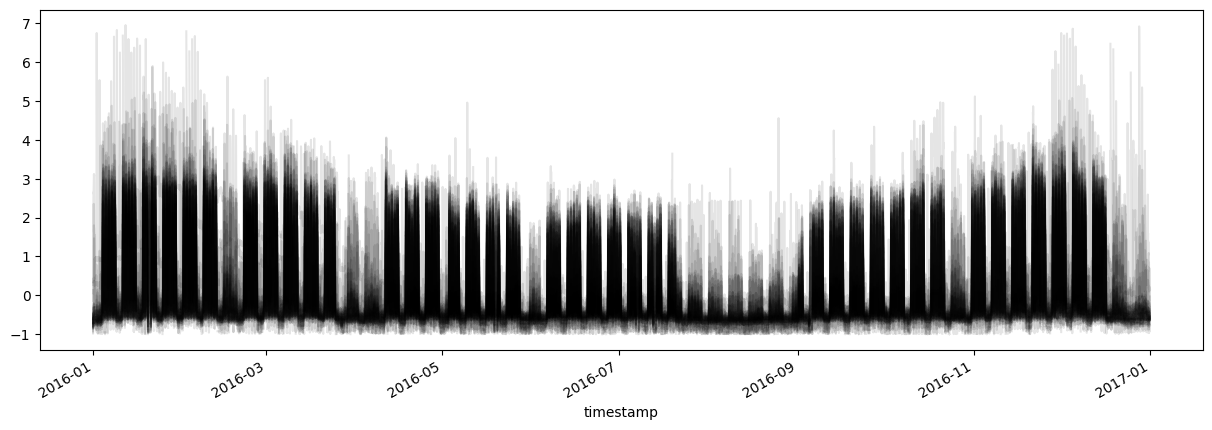

-----------------------------------------------------------------------------------


In [27]:
df_PM_temp['ClusterNo'] = Kmeans_clustering(df=df_PM_temp.fillna(0), clusterNum=bestClusterNum_dept, max_iter=10000, n_jobs=-1)

for ClusterNo in df_PM_temp['ClusterNo'].sort_values().unique():
    df_plot = df_PM_temp[df_PM_temp['ClusterNo']==ClusterNo].T.drop('ClusterNo')
    df_plot = np.expm1(df_plot)
    print('Cluster No.: ' + str(ClusterNo))    
    print('Amount of meters: ' + str(len(df_plot.T)))
    df_plot.plot(figsize=(15,5),color='black',alpha=0.1,legend=False)
    plt.show()
    print('-----------------------------------------------------------------------------------')

In [28]:
test_features = test_features.merge(df_PM_temp['ClusterNo'].reset_index(),on='building_id',how='left')

In [29]:
def impute_nulls(data):
    # FIX: Select the column before calling .mean()
    mean_reading = data.groupby('building_id')['meter_reading'].mean()

    building_id = mean_reading.index
    values = mean_reading.values
    
    for i, idx in tqdm(enumerate(building_id)):
        data[data['building_id']==idx] = data[data['building_id']==idx].fillna(values[i]) 
    
    return data

# Now both of these will run perfectly
# train_features = impute_nulls(train_features)
test_features = impute_nulls(test_features)

206it [01:42,  2.02it/s]


In [30]:
#value change features(diff)
test_feature = pd.read_csv('/kaggle/input/competitions/energy-anomaly-detection/test_features.csv')
for shift_hours in tqdm(list(np.arange(-24,0))+list(np.arange(1,24+1))+list(np.arange(-24*7,-24,24))+list(np.arange(24+24,24*7+1,24))):
    shift_hours = int(shift_hours)
    meter_reading_shift = test_feature[['building_id', 'timestamp', 'meter_reading']]
    meter_reading_shift['timestamp'] = pd.to_datetime(meter_reading_shift['timestamp']) + datetime.timedelta(hours=shift_hours)
    meter_reading_shift['timestamp'] = meter_reading_shift['timestamp'].astype('str')
    meter_reading_shift = meter_reading_shift.rename(columns={'meter_reading':'lag_value_'+str(shift_hours)})
    test_feature = test_feature.merge(meter_reading_shift, on=['building_id', 'timestamp'], how='left')
    
    test_features['lag_value_'+str(shift_hours)] = test_feature['lag_value_'+str(shift_hours)]-test_feature['meter_reading']

100%|██████████| 60/60 [04:33<00:00,  4.55s/it]


In [31]:
#value change features(ratio)
test_feature = pd.read_csv('/kaggle/input/competitions/energy-anomaly-detection/test_features.csv')
for shift_hours in tqdm(list(np.arange(-24,0))+list(np.arange(1,24+1))+list(np.arange(-24*7,-24,24))+list(np.arange(24+24,24*7+1,24))):
    shift_hours = int(shift_hours)
    meter_reading_shift = test_feature[['building_id', 'timestamp', 'meter_reading']]
    meter_reading_shift['timestamp'] = pd.to_datetime(meter_reading_shift['timestamp']) + datetime.timedelta(hours=shift_hours)
    meter_reading_shift['timestamp'] = meter_reading_shift['timestamp'].astype('str')
    meter_reading_shift = meter_reading_shift.rename(columns={'meter_reading':'lag_value_'+str(shift_hours)})
    test_feature = test_feature.merge(meter_reading_shift, on=['building_id', 'timestamp'], how='left')
    
    test_features['lag_value_ratio_'+str(shift_hours)] = (test_feature['lag_value_'+str(shift_hours)]+1)/(test_feature['meter_reading']+1)

100%|██████████| 60/60 [04:43<00:00,  4.72s/it]


In [32]:
df_savgol_test = []

for building_id in tqdm(test_features['building_id'].unique()):
    df_temp = test_features[test_features['building_id']==building_id]
    df_temp['meter_reading_smooth'] = savgol_filter(df_temp['meter_reading'].fillna(method='ffill'), 5, 3)
    df_temp['Residual_savgol_w5p3'] = (df_temp['meter_reading'] - df_temp['meter_reading_smooth'])
    df_savgol_test.append(df_temp)
    
df_savgol_test = pd.concat(df_savgol_test,axis=0).sort_index()
df_savgol_test


100%|██████████| 206/206 [00:09<00:00, 22.54it/s]


,building_id,timestamp,meter_reading,site_id,primary_use,square_feet,year_built,floor_count,air_temperature,cloud_coverage,...,lag_value_ratio_-72,lag_value_ratio_-48,lag_value_ratio_48,lag_value_ratio_72,lag_value_ratio_96,lag_value_ratio_120,lag_value_ratio_144,lag_value_ratio_168,meter_reading_smooth,Residual_savgol_w5p3
0,18,2016-01-01 00:00:00,594.902165,0,Education,111891,96,0,19.4,10,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,594.902165,1.136868e-13
1,19,2016-01-01 00:00:00,60.181135,0,Office,18717,104,0,19.4,10,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60.181135,6.394885e-14
2,26,2016-01-01 00:00:00,47.831186,0,Office,26953,105,0,19.4,10,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,47.831186,1.421085e-14
3,38,2016-01-01 00:00:00,143.504764,0,Office,12769,113,0,19.4,10,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,143.504764,5.684342e-14
4,39,2016-01-01 00:00:00,98.132823,0,Office,64619,69,0,19.4,10,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,98.132823,0.000000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1800562,1320,2016-12-31 23:00:00,74.552000,14,Entertainment/public assembly,34565,255,0,-29.9,10,...,NaN,NaN,1.341778,1.343035,1.693165,1.158010,1.013024,0.999841,75.227471,-6.754714e-01
1800563,1321,2016-12-31 23:00:00,584.000000,14,Entertainment/public assembly,370024,255,0,-29.9,10,...,NaN,NaN,1.454701,1.454701,0.900855,0.921368,0.834188,0.497436,591.214286,-7.214286e+00
1800564,1322,2016-12-31 23:00:00,131.596000,14,Entertainment/public assembly,166489,255,0,-29.9,10,...,NaN,NaN,0.962299,0.921053,0.869627,0.921053,0.937140,0.853540,132.624400,-1.028400e+00
1800565,1384,2016-12-31 23:00:00,1.200000,15,Education,56969,67,0,-29.9,10,...,NaN,NaN,1.000000,1.022727,1.000000,1.034091,1.011364,0.875000,1.201786,-1.785714e-03


In [33]:
test_features['Residual_savgol_w5p3'] = df_savgol_test['Residual_savgol_w5p3']

In [34]:
test_features.to_pickle('test_features.pickle')
test_features

,building_id,timestamp,meter_reading,site_id,primary_use,square_feet,year_built,floor_count,air_temperature,cloud_coverage,...,lag_value_ratio_-96,lag_value_ratio_-72,lag_value_ratio_-48,lag_value_ratio_48,lag_value_ratio_72,lag_value_ratio_96,lag_value_ratio_120,lag_value_ratio_144,lag_value_ratio_168,Residual_savgol_w5p3
0,18,2016-01-01 00:00:00,594.902165,0,Education,111891,96,0,19.4,10,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.136868e-13
1,19,2016-01-01 00:00:00,60.181135,0,Office,18717,104,0,19.4,10,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.394885e-14
2,26,2016-01-01 00:00:00,47.831186,0,Office,26953,105,0,19.4,10,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.421085e-14
3,38,2016-01-01 00:00:00,143.504764,0,Office,12769,113,0,19.4,10,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.684342e-14
4,39,2016-01-01 00:00:00,98.132823,0,Office,64619,69,0,19.4,10,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1800562,1320,2016-12-31 23:00:00,74.552000,14,Entertainment/public assembly,34565,255,0,-29.9,10,...,NaN,NaN,NaN,1.341778,1.343035,1.693165,1.158010,1.013024,0.999841,-6.754714e-01
1800563,1321,2016-12-31 23:00:00,584.000000,14,Entertainment/public assembly,370024,255,0,-29.9,10,...,NaN,NaN,NaN,1.454701,1.454701,0.900855,0.921368,0.834188,0.497436,-7.214286e+00
1800564,1322,2016-12-31 23:00:00,131.596000,14,Entertainment/public assembly,166489,255,0,-29.9,10,...,NaN,NaN,NaN,0.962299,0.921053,0.869627,0.921053,0.937140,0.853540,-1.028400e+00
1800565,1384,2016-12-31 23:00:00,1.200000,15,Education,56969,67,0,-29.9,10,...,NaN,NaN,NaN,1.000000,1.022727,1.000000,1.034091,1.011364,0.875000,-1.785714e-03


In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
from tqdm import tqdm, trange
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn import metrics
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.ensemble import HistGradientBoostingClassifier

from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import RandomOverSampler

import lightgbm as lgb

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objs as go
import plotly
from plotly.offline import download_plotlyjs, init_notebook_mode, plot, iplot
import cufflinks as cf
cf.set_config_file(offline=True)
# Input data files are available i

import datetime

import warnings
warnings.filterwarnings('ignore')

In [36]:
train_features['dayofyear'] = pd.to_datetime(train_features['timestamp']).dt.dayofyear+pd.to_datetime(train_features['timestamp']).dt.hour/24
test_features['dayofyear'] = pd.to_datetime(test_features['timestamp']).dt.dayofyear+pd.to_datetime(test_features['timestamp']).dt.hour/24

In [37]:
#Downsampling
neg = train_features[train_features['anomaly'] == 0]
pos = train_features[train_features['anomaly'] == 1]

print(neg.shape, pos.shape)
negs1 = neg.sample(n = pos.shape[0], random_state=10)
negs2 = neg.sample(n = pos.shape[0], random_state=20)
df_eq = pd.concat([negs1, pos, negs2, pos], axis=0)
print(df_eq.shape)

(1712198, 58) (37296, 58)
(149184, 58)


In [38]:
list_variables = list(df_eq.drop(['anomaly',
                                  'wind_direction',
                                  'air_temperature_std_lag73'],axis=1).select_dtypes(include=['float','int']).columns)

In [39]:
features = df_eq.drop(['anomaly'], axis=1)
features = features[list_variables]
target = df_eq['anomaly']

In [40]:
#Data split for taining and validation data
X_train = features[features['building_id']%5<4]
X_val = features[features['building_id']%5==4]
Y_train = target[features['building_id']%5<4]
Y_val = target[features['building_id']%5==4]

print(X_train.shape, X_val.shape)

(119520, 47) (29664, 47)


In [41]:
#Normalization
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
test = scaler.transform(test_features[list_variables])

In [42]:
#XGBoost modeling
xgb_model = XGBClassifier(n_estimators=100)
xgb_model.fit(X_train, Y_train)

pred_train_xgb = xgb_model.predict_proba(X_train)[:,1]
pred_val_xgb = xgb_model.predict_proba(X_val)[:,1]

score_train_xgb = metrics.roc_auc_score(Y_train, pred_train_xgb)
score_val_xgb = metrics.roc_auc_score(Y_val, pred_val_xgb)

print('Training Accuracy : ', score_train_xgb)
print('Validation Accuracy : ', score_val_xgb)

Training Accuracy :  0.9974133104453291
Validation Accuracy :  0.8805357897672762


In [43]:
#HistGradientBoosting modeling
hist_model = HistGradientBoostingClassifier()
hist_model.fit(np.nan_to_num(X_train), Y_train)

pred_train_hist = hist_model.predict_proba(np.nan_to_num(X_train))[:,1]
pred_val_hist = hist_model.predict_proba(np.nan_to_num(X_val))[:,1]

score_train_hist = metrics.roc_auc_score(Y_train, pred_train_hist)
score_val_hist = metrics.roc_auc_score(Y_val, pred_val_hist)

print('Training Accuracy : ', score_train_hist)
print('Validation Accuracy : ', score_val_hist)

Training Accuracy :  0.9856295116224172
Validation Accuracy :  0.8874250998039048


In [44]:
#Catboost modeling
cat_model = CatBoostClassifier()
cat_model.fit(X_train, Y_train, silent=True)

pred_train_cat = cat_model.predict_proba(X_train)[:,1]
pred_val_cat = cat_model.predict_proba(X_val)[:,1]

score_train_cat = metrics.roc_auc_score(Y_train, pred_train_cat)
score_val_cat = metrics.roc_auc_score(Y_val, pred_val_cat)

print('Training Accuracy : ', score_train_cat)
print('Validation Accuracy : ', score_val_cat)

Training Accuracy :  0.9984079981951295
Validation Accuracy :  0.8895911905587826


In [45]:
#LightGBM modeling
lgb_model = lgb.LGBMClassifier(n_estimators=100)
lgb_model.fit(X_train, Y_train)

pred_train_lgb = lgb_model.predict_proba(X_train)[:,1]
pred_val_lgb = lgb_model.predict_proba(X_val)[:,1]

score_train_lgb = metrics.roc_auc_score(Y_train, pred_train_lgb)
score_val_lgb = metrics.roc_auc_score(Y_val, pred_val_lgb)

print('Training Accuracy : ', score_train_lgb)
print('Validation Accuracy : ', score_val_lgb)

[LightGBM] [Info] Number of positive: 59058, number of negative: 60462
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.014413 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 5441
[LightGBM] [Info] Number of data points in the train set: 119520, number of used features: 45
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.494127 -> initscore=-0.023495
[LightGBM] [Info] Start training from score -0.023495
Training Accuracy :  0.9858806611803507
Validation Accuracy :  0.89186580749612


In [46]:
#Model ensembling
score_train_ensemble = metrics.roc_auc_score(Y_train, (pred_train_xgb+pred_train_cat+pred_train_lgb+pred_train_hist)/4)
score_val_ensemble = metrics.roc_auc_score(Y_val, (pred_val_xgb+pred_val_cat+pred_val_lgb+pred_val_hist)/4)

print('Training Accuracy : ', score_train_ensemble)
print('Validation Accuracy : ', score_val_ensemble)

Training Accuracy :  0.9964889034377049
Validation Accuracy :  0.8980484604189007


In [47]:
# 1. Prepare the final training data (X_all)
# We scale the full downsampled 'features' dataframe, just like X_train/X_val were scaled earlier
X_all = scaler.transform(features)

# 2. Train the models on X_all and target
# Both come from the downsampled 'df_eq', so their lengths will match perfectly
lgb_model.fit(X_all, target)
xgb_model.fit(X_all, target)
cat_model.fit(X_all, target, silent=True)
hist_model.fit(np.nan_to_num(X_all), target)

# 3. Generate predictions using 'test'
# 'test' was already cleaned and scaled earlier in the notebook, so it is perfectly formatted
predictions = (xgb_model.predict_proba(test)[:,1]/4 + 
               lgb_model.predict_proba(test)[:,1]/4 + 
               cat_model.predict_proba(test)[:,1]/4 + 
               hist_model.predict_proba(np.nan_to_num(test))[:,1]/4)

print("Predictions successfully generated!")

[LightGBM] [Info] Number of positive: 74592, number of negative: 74592
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.019130 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 5598
[LightGBM] [Info] Number of data points in the train set: 149184, number of used features: 45
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
Predictions successfully generated!


In [48]:
ss = pd.read_csv('/kaggle/input/competitions/energy-anomaly-detection/sample_submission.csv')
ss['anomaly'] = predictions
ss.loc[test_features['meter_reading']==1.0, 'anomaly'] = 1

ss.loc[(test_features['dayofyear']==1)&((test_features['building_id']>145)|(test_features['building_id']<105)),'anomaly'] = 0
ss.loc[test_features['dayofyear']>366.9583,'anomaly'] = 0

ss.to_csv('Submission_lgb_xgb.csv', index=False)
ss

,row_id,anomaly
0,0,0.0
1,1,0.0
2,2,0.0
3,3,0.0
4,4,0.0
...,...,...
1800562,1800562,0.0
1800563,1800563,0.0
1800564,1800564,0.0
1800565,1800565,0.0


In [49]:
import time
import resource

# Calculate total time
notebook_end_time = time.time()
total_seconds = notebook_end_time - notebook_start_time
total_minutes = total_seconds / 60

# Get peak memory usage (resource returns kilobytes on Linux/Kaggle)
peak_memory_kb = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
peak_memory_mb = peak_memory_kb / 1024

# Generate the final report
print("="*40)
print("🚀 AUTOMATED EXECUTION REPORT")
print("="*40)
print(f"Total Execution Time: {total_minutes:.2f} minutes ({total_seconds:.1f} seconds)")
print(f"Peak System RAM Used: {peak_memory_mb:.2f} MB")
print("="*40)

🚀 AUTOMATED EXECUTION REPORT
Total Execution Time: 26.64 minutes (1598.3 seconds)
Peak System RAM Used: 21716.84 MB
